# Module 06, Part 4: LoRA, adapting with a low-rank update

This notebook is the runnable companion to Part 4 of the Module 06 learning content.
It checks, with code:

1. A LoRA layer starts exactly equal to the layer it wraps, and merging it afterwards
   changes nothing.
2. The parameter saving, and why $B$ must start at zero while $A$ starts random.
3. An experiment: a small network is pretrained on digits, then adapted to three kinds
   of change, by training only the head, by LoRA at several ranks, and by full
   fine-tuning.
4. Whether the update full fine-tuning chooses is really low-rank, measured with a
   singular value decomposition.
5. Whether LoRA's shortfall comes from the rank or from the training settings.

The network is a small MLP on 8 by 8 digit images, with only 100 images for adaptation.
It shows the mechanics. It is not an LLM and it does not tell you how much rank a large
model needs.

In [1]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.15.0+cpu


## 1. A LoRA layer

The layer keeps the pretrained weight $W$ frozen and adds a low-rank update:

$$W' = W + \frac{\alpha}{r} B A$$

with $A$ of shape $(r, k)$ and $B$ of shape $(d, r)$ for a $d \times k$ matrix $W$.
$A$ starts as small random numbers and $B$ starts at zero.

In [2]:
import math

import torch
import torch.nn as nn


class LoRALinear(nn.Module):
    """Wrap a frozen nn.Linear and add the low-rank update (alpha / r) * B A.

    A is (r, in_features), random. B is (out_features, r), zero. So the layer
    starts exactly equal to the wrapped layer.
    """

    def __init__(self, base, r, alpha=None, zero_B=True):
        super().__init__()
        self.base, self.r = base, r
        self.alpha = alpha if alpha is not None else r
        for p in self.base.parameters():
            p.requires_grad_(False)
        self.A = nn.Parameter(torch.empty(r, base.in_features))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r) if zero_B
                              else torch.randn(base.out_features, r) * 0.01)
        self.scale = self.alpha / r

    def forward(self, x):
        return self.base(x) + self.scale * (x @ self.A.T) @ self.B.T

    @torch.no_grad()
    def merged(self):
        """A single nn.Linear holding W + (alpha / r) B A, with no extra cost at inference."""
        out = nn.Linear(self.base.in_features, self.base.out_features)
        out.weight.copy_(self.base.weight + self.scale * self.B @ self.A)
        out.bias.copy_(self.base.bias)
        return out


def add_lora(mlp, r, alpha=None):
    """Replace the hidden Linear layers of a Sequential MLP with LoRA layers.

    The last Linear (the head) stays frozen and unwrapped. Returns a new Sequential;
    the original is not modified.
    """
    import copy
    net = copy.deepcopy(mlp)
    linears = [i for i, m in enumerate(net) if isinstance(m, nn.Linear)]
    for i in linears[:-1]:
        net[i] = LoRALinear(net[i], r, alpha)
    for p in net[linears[-1]].parameters():
        p.requires_grad_(False)
    return net


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [3]:
base = nn.Linear(768, 768)
layer = LoRALinear(base, r=8, alpha=16)
x = torch.randn(4, 768)

print("output equals the wrapped layer at initialization:", torch.allclose(layer(x), base(x)))
n_full, n_lora = base.weight.numel(), layer.A.numel() + layer.B.numel()
print(f"weights in W: {n_full:,}   in A and B at rank 8: {n_lora:,}   ({100 * n_lora / n_full:.1f}% as many)")
print("trainable parameters in the layer:", count_trainable(layer), "(A and B only; the bias and W are frozen)")

# train A and B for a few steps so that B is no longer zero, then merge
opt = torch.optim.Adam([layer.A, layer.B], 1e-2)
target = torch.randn(4, 768)
for _ in range(20):
    loss = F.mse_loss(layer(x), target)
    opt.zero_grad(); loss.backward(); opt.step()
merged = layer.merged()
print("after training, merged layer equals the two-path layer:", torch.allclose(layer(x), merged(x), atol=1e-4))
print(f"largest difference: {(layer(x) - merged(x)).abs().max().item():.2e}")

output equals the wrapped layer at initialization: True
weights in W: 589,824   in A and B at rank 8: 12,288   (2.1% as many)
trainable parameters in the layer: 12288 (A and B only; the bias and W are frozen)
after training, merged layer equals the two-path layer: True
largest difference: 1.19e-06


### Why $B$ starts at zero and $A$ starts random

If both start at zero, the gradient with respect to each is proportional to the other,
so both gradients are zero and nothing ever trains. With $B = 0$ and $A$ random, the
gradient of $B$ is not zero, and once $B$ moves, $A$ receives gradient as well.

In [4]:
def grad_norms(zero_A):
    layer = LoRALinear(nn.Linear(32, 32), r=4)
    if zero_A:
        nn.init.zeros_(layer.A)
    loss = F.mse_loss(layer(torch.randn(8, 32)), torch.randn(8, 32))
    loss.backward()
    return layer.A.grad.norm().item(), layer.B.grad.norm().item()

print("A random, B zero:  grad of A = %.4f, grad of B = %.4f" % grad_norms(zero_A=False))
print("A zero,   B zero:  grad of A = %.4f, grad of B = %.4f" % grad_norms(zero_A=True))

A random, B zero:  grad of A = 0.0000, grad of B = 0.2280
A zero,   B zero:  grad of A = 0.0000, grad of B = 0.0000


With $A$ random the gradient of $B$ is non-zero (and the gradient of $A$ is zero only
for this first step, because $B$ is zero). With both at zero, neither moves, ever.

## 2. The experiment

A network with 64 inputs, two hidden layers of 256 units and 10 outputs (85,002
parameters) is pretrained for 600 updates on 1,257 digit images. It is then adapted to
images changed in one of three ways, using only the first 100 changed images of a
540-image held-out pool, and tested on the other 440 changed images:

- **Mild.** Every pixel becomes $0.6 \times$ the old value $+ 0.2$ (dimmer, lower contrast).
- **Roll.** The whole image moves one pixel to the right.
- **Invert.** Each pixel becomes 1 minus its old value (dark digits on a light background).

Methods: no adaptation; training only the final layer (the head); full fine-tuning; and
LoRA on the two hidden layers at ranks 1, 2, 4, 8 and 16, with $\alpha = 2r$ and the head
frozen. All use 300 Adam updates, learning rate 0.001 for the head and full runs and
0.003 for LoRA. We report the mean accuracy over five seeds, where the seed changes the
pretraining and the LoRA initialization.

In [5]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SHIFTS = {
    "mild": lambda x: 0.6 * x + 0.2,
    "roll": lambda x: np.roll(x.reshape(-1, 8, 8), 1, axis=2).reshape(-1, 64),
    "invert": lambda x: 1.0 - x,
}


def load_data():
    """1,257 pretraining images and 540 held-out images (fixed split)."""
    d = load_digits()
    X, y = d.data / 16.0, d.target
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
    t = lambda a: torch.tensor(a, dtype=torch.float32)
    return t(Xtr), torch.tensor(ytr), t(Xte), torch.tensor(yte)


def make_mlp():
    return nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 10))


def accuracy(net, X, y):
    with torch.no_grad():
        return (net(X).argmax(1) == y).float().mean().item()


def pretrain(seed, data, steps=600, batch_size=64, lr=1e-3):
    Xtr, ytr, _, _ = data
    torch.manual_seed(seed)
    net = make_mlp()
    opt = torch.optim.Adam(net.parameters(), lr)
    g = torch.Generator().manual_seed(seed)
    for _ in range(steps):
        i = torch.randint(0, len(Xtr), (batch_size,), generator=g)
        loss = nn.functional.cross_entropy(net(Xtr[i]), ytr[i])
        opt.zero_grad(); loss.backward(); opt.step()
    return net


def shifted_split(data, shift, n_adapt=100):
    """Shift the held-out images; the first n_adapt are for adaptation, the rest for evaluation."""
    _, _, Xte, yte = data
    Xs = torch.tensor(SHIFTS[shift](Xte.numpy()), dtype=torch.float32)
    return Xs[:n_adapt], yte[:n_adapt], Xs[n_adapt:], yte[n_adapt:]


def adapt(net, Xa, ya, params, steps=300, lr=1e-3):
    """Full-batch Adam on the given parameters only. Returns the (modified) network."""
    opt = torch.optim.Adam(params, lr)
    for _ in range(steps):
        loss = nn.functional.cross_entropy(net(Xa), ya)
        opt.zero_grad(); loss.backward(); opt.step()
    return net

In [6]:
data = load_data()
print("pretraining images:", len(data[0]), "  held-out pool:", len(data[2]))

def run_methods(seed, ranks=(1, 2, 4, 8, 16)):
    base = pretrain(seed, data)
    out = {"pretrained": accuracy(base, data[2], data[3])}
    for shift in SHIFTS:
        Xa, ya, Xe, ye = shifted_split(data, shift)
        out[(shift, "none")] = accuracy(base, Xe, ye)

        net = copy.deepcopy(base)
        for p in net.parameters():
            p.requires_grad_(False)
        for p in net[-1].parameters():
            p.requires_grad_(True)
        adapt(net, Xa, ya, [p for p in net.parameters() if p.requires_grad], lr=1e-3)
        out[(shift, "head")] = accuracy(net, Xe, ye)

        net = copy.deepcopy(base)
        adapt(net, Xa, ya, list(net.parameters()), lr=1e-3)
        out[(shift, "full")] = accuracy(net, Xe, ye)

        for r in ranks:
            torch.manual_seed(seed)
            net = add_lora(base, r, alpha=2 * r)
            adapt(net, Xa, ya, [p for p in net.parameters() if p.requires_grad], lr=3e-3)
            out[(shift, f"lora{r}")] = accuracy(net, Xe, ye)
    return out

runs = [run_methods(seed) for seed in range(5)]
mean = lambda key: float(np.mean([r[key] for r in runs]))
std = lambda key: float(np.std([r[key] for r in runs]))
print(f"accuracy of the pretrained network on held-out digits: {mean('pretrained'):.3f}")

pretraining images: 1257   held-out pool: 540
accuracy of the pretrained network on held-out digits: 0.975


In [7]:
methods = [("No adaptation", "none", 0), ("Head only", "head", 2570)] + \
          [(f"LoRA, r = {r}", f"lora{r}", count_trainable(add_lora(make_mlp(), r))) for r in (1, 2, 4, 8, 16)] + \
          [("Full fine-tuning", "full", 85002)]
print(f"{'method':18s}{'trainable':>10s}{'mild':>9s}{'roll':>9s}{'invert':>9s}")
for name, key, n in methods:
    print(f"{name:18s}{n:10,d}" + "".join(f"{mean((s, key)):9.3f}" for s in SHIFTS))
print()
print("standard deviation over seeds, roll shift:", {k: round(std(('roll', k)), 3) for _, k, _ in methods})

method             trainable     mild     roll   invert
No adaptation              0    0.896    0.468    0.012
Head only              2,570    0.941    0.785    0.853
LoRA, r = 1              832    0.938    0.805    0.103
LoRA, r = 2            1,664    0.931    0.841    0.163
LoRA, r = 4            3,328    0.931    0.858    0.312
LoRA, r = 8            6,656    0.922    0.860    0.504
LoRA, r = 16          13,312    0.924    0.864    0.622
Full fine-tuning      85,002    0.939    0.870    0.868

standard deviation over seeds, roll shift: {'none': 0.011, 'head': 0.006, 'lora1': 0.01, 'lora2': 0.004, 'lora4': 0.012, 'lora8': 0.004, 'lora16': 0.008, 'full': 0.004}


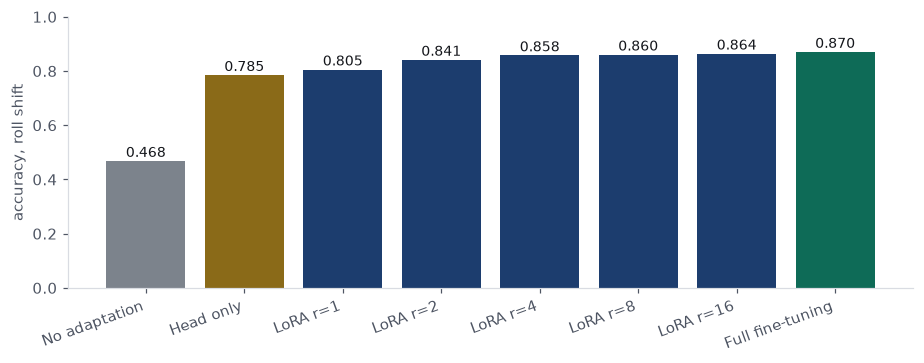

In [8]:
keys = [("No adaptation", "none"), ("Head only", "head")] + [(f"LoRA r={r}", f"lora{r}") for r in (1, 2, 4, 8, 16)] + [("Full fine-tuning", "full")]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
vals = [mean(("roll", k)) for _, k in keys]
cols = [MUTED, AMBER] + [NAVY] * 5 + [GREEN]
ax.bar([n for n, _ in keys], vals, color=cols)
for i, v in enumerate(vals):
    ax.text(i, v + 0.015, f"{v:.3f}", ha="center", fontsize=9, color=INK)
ax.set_ylim(0, 1.0); ax.set_ylabel("accuracy, roll shift"); ax.grid(False)
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

Read the three columns separately, because they tell three different stories.

- **Mild shift: everything works.** The five adapted methods are within 0.02 of each
  other (0.923 to 0.941), against 0.897 with no adaptation, and the seed-to-seed spread
  on the roll shift was about 0.01, so read these as tied. A small change in the data
  needs a small change in the model. Even rank 1, with 832 trainable parameters (about
  1% of the network), is enough.
- **Roll shift: rank matters.** LoRA climbs with the rank, from 0.813 at rank 1 to 0.864
  at rank 16, and passes the head-only run (0.785) at every rank. Rank 16 is within 0.007
  of full fine-tuning (0.871) while training 13,312 parameters against 85,002.
- **Invert shift: LoRA struggles.** Rank 1 is at chance (0.103). Accuracy rises with rank
  to 0.614 at rank 16, but that is far below full fine-tuning (0.866). Training only the
  head, with 2,570 parameters, reaches 0.852, so the pretrained features were still
  usable and the shortfall belongs to LoRA's update, not to the network. Why LoRA lags
  the head-only run here is not something this experiment isolates; item 1 of the Try it
  list is the first thing to test.

## 3. Is the update really low-rank?

LoRA bets that the change a task needs is concentrated in a few directions. We can test
the bet directly. After full fine-tuning on the roll shift, take the change in each
hidden layer, $\Delta W$, and measure how much of its squared size lies in its largest
few singular directions.

In [9]:
def energy_in_top(dW, k):
    s = torch.linalg.svdvals(dW) ** 2
    return (s[:k].sum() / s.sum()).item()

rows = {"256 x 256 layer": [], "256 x 64 layer": []}
Xa, ya, Xe, ye = shifted_split(data, "roll")
for seed in range(5):
    base = pretrain(seed, data)
    net = copy.deepcopy(base)
    adapt(net, Xa, ya, list(net.parameters()), lr=1e-3)
    for name, idx in (("256 x 256 layer", 2), ("256 x 64 layer", 0)):
        dW = (net[idx].weight - base[idx].weight).detach()
        rows[name].append([energy_in_top(dW, k) for k in (1, 4, 16)])

print(f"{'':18s}{'top 1':>8s}{'top 4':>8s}{'top 16':>8s}   (share of the squared size of the update)")
for name, v in rows.items():
    m = np.mean(v, axis=0)
    print(f"{name:18s}{m[0]:8.3f}{m[1]:8.3f}{m[2]:8.3f}")

                     top 1   top 4  top 16   (share of the squared size of the update)
256 x 256 layer      0.301   0.712   0.947
256 x 64 layer       0.225   0.626   0.944


The update that full fine-tuning chose is concentrated, not exactly low-rank. For the
256 by 256 layer the top 4 directions hold 71% of its squared size and the top 16 hold
95%. For the 256 by 64 layer they hold 63% and 94%. That is the property LoRA relies on,
and it also fits the roll column above: rank 4 leaves nearly a third of the update
unexplained and trails rank 16.

## 4. Is LoRA's gap the rank or the training settings?

A LoRA run that looks weak has two possible explanations: the rank is too small, or the
training was not tuned for LoRA. We separate them on the roll and invert shifts with
three seeds: LoRA at ranks 16 and 64, a higher learning rate of 0.01, and 300 or 1,500
updates. Full fine-tuning is shown with the same two lengths.

In [10]:
second = {}
for seed in range(3):
    base = pretrain(seed, data)
    for shift in ("roll", "invert"):
        Xa, ya, Xe, ye = shifted_split(data, shift)
        for steps in (300, 1500):
            net = copy.deepcopy(base)
            adapt(net, Xa, ya, list(net.parameters()), steps=steps, lr=1e-3)
            second.setdefault((shift, f"full, {steps} updates"), []).append(accuracy(net, Xe, ye))
            for r in (16, 64):
                torch.manual_seed(seed)
                net = add_lora(base, r, alpha=2 * r)
                adapt(net, Xa, ya, [p for p in net.parameters() if p.requires_grad], steps=steps, lr=1e-2)
                second.setdefault((shift, f"LoRA r={r}, {steps} updates"), []).append(accuracy(net, Xe, ye))

names = [f"full, {s} updates" for s in (300, 1500)] + [f"LoRA r={r}, {s} updates" for r in (16, 64) for s in (300, 1500)]
print(f"{'':26s}{'roll':>8s}{'invert':>8s}")
for n in names:
    print(f"{n:26s}" + "".join(f"{np.mean(second[(s, n)]):8.3f}" for s in ("roll", "invert")))

                              roll  invert
full, 300 updates            0.869   0.870
full, 1500 updates           0.875   0.873
LoRA r=16, 300 updates       0.856   0.559
LoRA r=16, 1500 updates      0.859   0.566
LoRA r=64, 300 updates       0.869   0.708
LoRA r=64, 1500 updates      0.864   0.711


On the roll shift the gap to full fine-tuning is a **rank** gap. Rank 64 reaches 0.870,
equal to full fine-tuning at 300 updates and at 1,500, while rank 16 stays at 0.856 or
0.857 whichever learning rate (0.003 earlier, 0.01 here) and training length is used.
Neither the higher learning rate nor five times longer training moves it.

On the invert shift rank helps (0.56 at rank 16, 0.69 to 0.70 at rank 64) but even rank
64 trained for 1,500 updates stays about 0.17 short of full fine-tuning (0.869). Note that
rank 64 is the full rank of the 256 by 64 first layer, so for that layer LoRA is no longer
low-rank at all, and the gap remains. Here the limit looks like capacity of the
hidden-layer update, which is the cost of LoRA stated plainly: a restricted update, in
exchange for far fewer trained parameters.

Two cautions. The settings in this section (the ranks, the learning rate of 0.01, the
longer runs) were chosen after seeing the results of section 2, and there is no separate
validation set, so treat the comparison as indicative and not as a benchmark. And only
three seeds were used here. In practice, retry a weak LoRA run at a higher rank and a
different learning rate before blaming the method, and report what you tried.

## Try it

1. Train the head as well as the LoRA matrices on the invert shift (set `requires_grad`
   on the last layer too). Does it close the gap to the head-only run?
2. Apply LoRA to the last hidden layer only instead of both. How does the roll accuracy
   at rank 8 change?
3. Change $\alpha$ from $2r$ to $r$ and to 16, keeping everything else fixed. How
   sensitive is the roll accuracy at rank 1 and at rank 16?
4. Repeat section 3 on the invert shift. Is the update that full fine-tuning chooses
   more or less concentrated than for the roll shift?

## What this notebook showed

- A LoRA layer is the frozen layer plus $(\alpha/r)BA$, equal to it at initialization
  and mergeable into a single matrix afterwards.
- Training $A$ and $B$ instead of $W$ trains a small fraction of the parameters. The
  bet that the useful change is low-rank holds well for small shifts and less well for
  large ones.
- When a LoRA run looks weak, check the rank and the training settings before blaming
  the method, and report what you tried.